In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns
%matplotlib inline

#  DATASET LOADING AND UNDERSTANDING

In [2]:
df = pd.read_csv("Data/raw_data/train.csv")

In [3]:
df.shape

(3000888, 6)

In [4]:
df.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB


In [6]:
df.describe()

,id,store_nbr,sales,onpromotion
count,3.000888e+06,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2.750000e+01,3.577757e+02,2.602770e+00
std,8.662819e+05,1.558579e+01,1.101998e+03,1.221888e+01
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,5.400000e+01,1.247170e+05,7.410000e+02


In [7]:
df.columns

Index(['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion'], dtype='object')

In [8]:
df.dtypes

id               int64
date            object
store_nbr        int64
family          object
sales          float64
onpromotion      int64
dtype: object

In [9]:
df.isnull().sum()

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df["sales"].describe()

count    3.000888e+06
mean     3.577757e+02
std      1.101998e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.958473e+02
max      1.247170e+05
Name: sales, dtype: float64

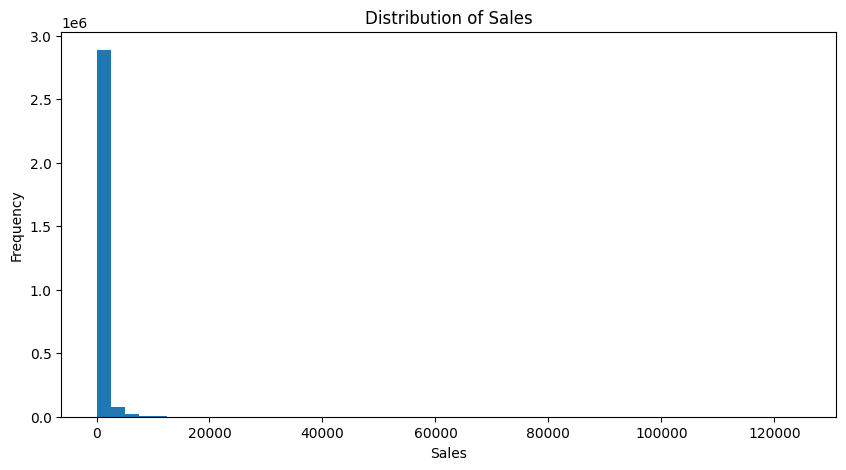

In [12]:
plt.figure(figsize=(10, 5))
plt.hist(df["sales"], bins=50)
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

In [13]:
# outlier detection using IQR
Q1 = df["sales"].quantile(0.25)
Q3 = df["sales"].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 0.0
Q3: 195.84725
IQR: 195.84725


In [14]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -293.770875
Upper Bound: 489.61812499999996


In [15]:
# no of potential outliers
outliers = df[df["sales"] > upper_bound]

print("Number of potential outliers:", len(outliers))

Number of potential outliers: 447105


In [16]:
# sales analysis by product family
family_sales = (df.groupby('family')['sales'].sum().sort_values(ascending = False))
family_sales.head(10)

family
GROCERY I        3.434627e+08
BEVERAGES        2.169545e+08
PRODUCE          1.227047e+08
CLEANING         9.752129e+07
DAIRY            6.448771e+07
BREAD/BAKERY     4.213395e+07
POULTRY          3.187600e+07
MEATS            3.108647e+07
PERSONAL CARE    2.459205e+07
DELI             2.411032e+07
Name: sales, dtype: float64

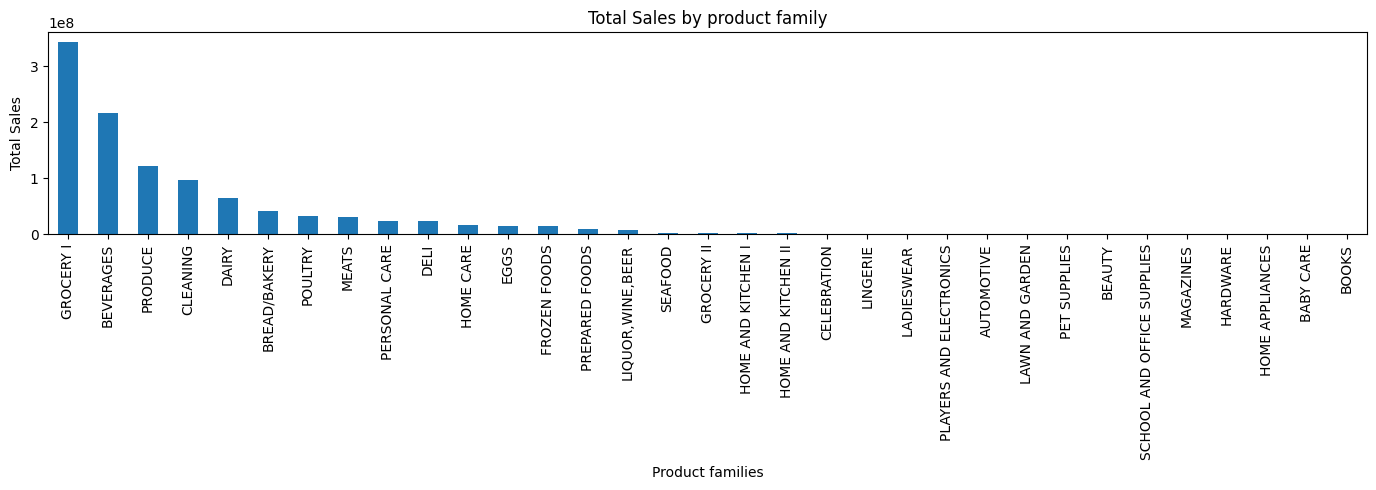

In [17]:
plt.figure(figsize = (14,5))
family_sales.plot(kind = 'bar')
plt.title('Total Sales by product family')
plt.xlabel('Product families')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

In [18]:
df['date'] = pd.to_datetime(df['date'])

In [19]:
print(df['date'].dtypes)

datetime64[ns]


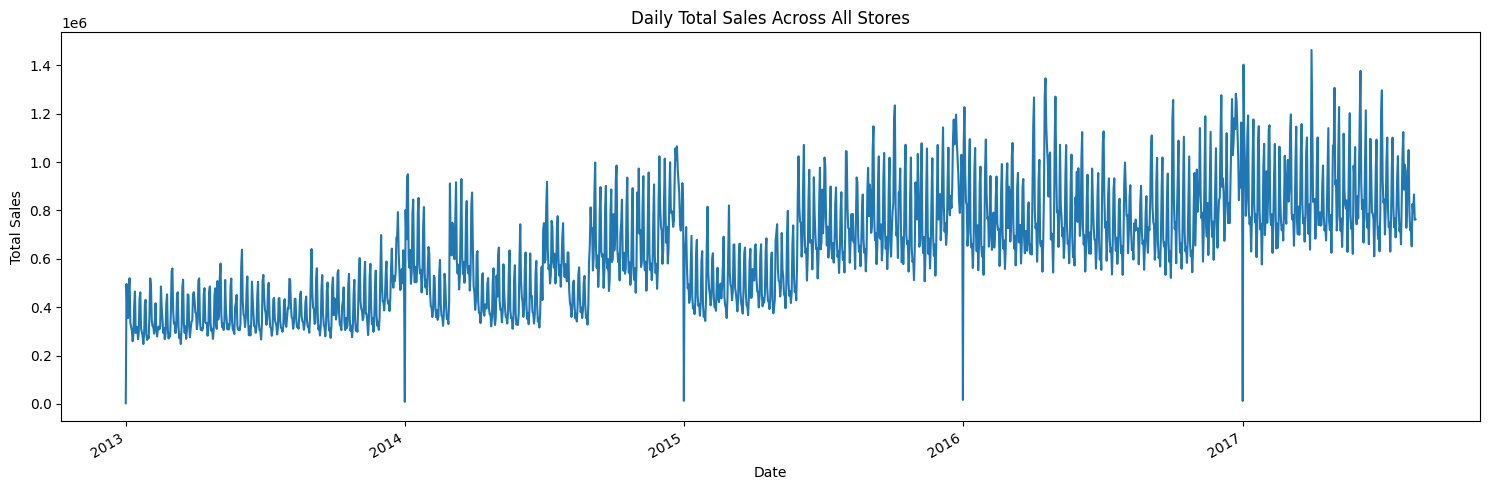

In [20]:
# daily sales trends 
daily_sales = df.groupby("date")["sales"].sum()
plt.figure(figsize=(15, 5))
daily_sales.plot()
plt.title("Daily Total Sales Across All Stores")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [21]:
df['day_of_week'] = df['date'].dt.day_name()

In [22]:
df.head()

,id,date,store_nbr,family,sales,onpromotion,day_of_week
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Tuesday
1,1,2013-01-01,1,BABY CARE,0.0,0,Tuesday
2,2,2013-01-01,1,BEAUTY,0.0,0,Tuesday
3,3,2013-01-01,1,BEVERAGES,0.0,0,Tuesday
4,4,2013-01-01,1,BOOKS,0.0,0,Tuesday


In [23]:
week_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

In [24]:
week_sales = df.groupby('day_of_week')["sales"].mean().reindex(week_order)

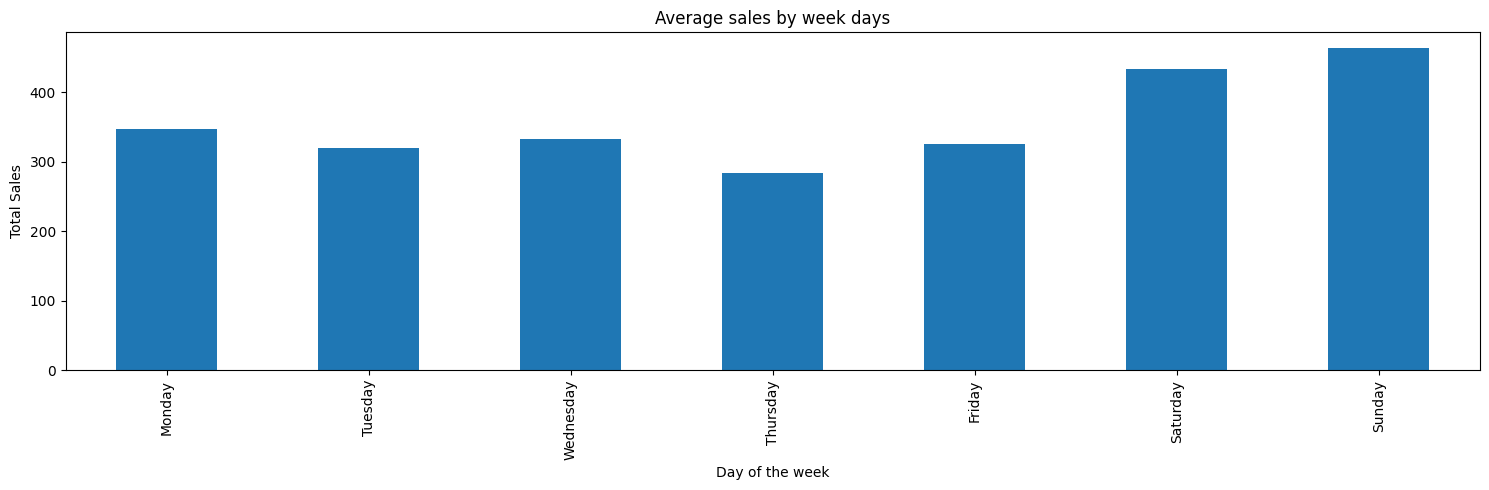

In [25]:

plt.figure(figsize=(15, 5))
week_sales.plot(kind = 'bar')
plt.title("Average sales by week days")
plt.xlabel("Day of the week")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [26]:
#month
df["month"] = df["date"].dt.month
df[["date", "month"]]

,date,month
0,2013-01-01,1
1,2013-01-01,1
2,2013-01-01,1
3,2013-01-01,1
4,2013-01-01,1
...,...,...
3000883,2017-08-15,8
3000884,2017-08-15,8
3000885,2017-08-15,8
3000886,2017-08-15,8


month
1     341.921554
2     320.928869
3     352.009294
4     339.199841
5     341.765820
6     353.597842
7     374.219111
8     336.992535
9     362.297418
10    362.407132
11    375.681762
12    453.740370
Name: sales, dtype: float64


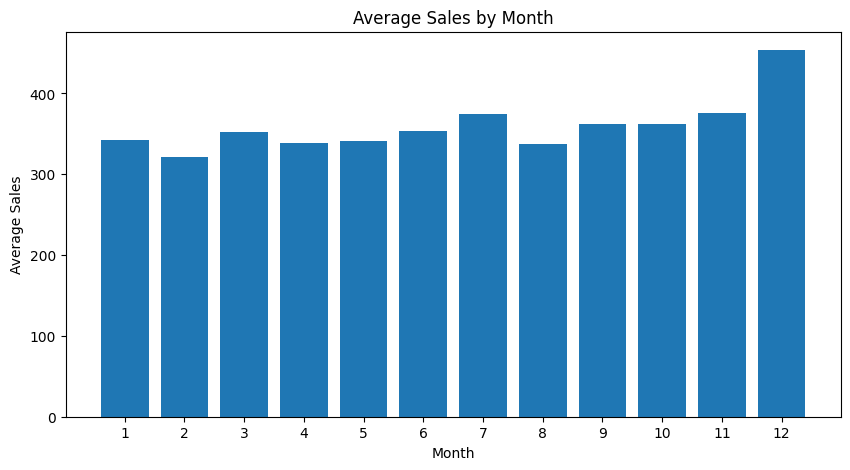

In [27]:

# Calculate average sales for each month
monthly_sales = df.groupby("month")["sales"].mean()

# Display the results
print(monthly_sales)

# Visualize monthly average sales
plt.figure(figsize=(10, 5))

plt.bar(monthly_sales.index, monthly_sales.values)

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.xticks(range(1, 13))

plt.show()


In [28]:
# Aggregate sales and promotions by date and product family
daily_data = df.groupby(
    ["date", "family"], as_index=False
).agg({
    "sales": "sum",
    "onpromotion": "sum"
})

# Sort records chronologically
daily_data = daily_data.sort_values(
    ["family", "date"]
).reset_index(drop=True)

# Display the result
print("Aggregated dataset shape:", daily_data.shape)
display(daily_data.head())

Aggregated dataset shape: (55572, 4)


,date,family,sales,onpromotion
0,2013-01-01,AUTOMOTIVE,0.0,0
1,2013-01-02,AUTOMOTIVE,255.0,0
2,2013-01-03,AUTOMOTIVE,161.0,0
3,2013-01-04,AUTOMOTIVE,169.0,0
4,2013-01-05,AUTOMOTIVE,342.0,0


In [29]:
# Extract date-related features
daily_data["day_of_week"] = daily_data["date"].dt.dayofweek
daily_data["month"] = daily_data["date"].dt.month
daily_data["day_of_year"] = daily_data["date"].dt.dayofyear

# Create lag features for each product family
daily_data["lag_1"] = daily_data.groupby("family")["sales"].shift(1)
daily_data["lag_7"] = daily_data.groupby("family")["sales"].shift(7)
daily_data["lag_14"] = daily_data.groupby("family")["sales"].shift(14)

# Create a 7-day rolling average using previous days only
daily_data["rolling_mean_7"] = (
    daily_data.groupby("family")["sales"]
    .transform(lambda x: x.shift(1).rolling(window=7).mean())
)

# Remove rows with missing lag or rolling values
daily_data = daily_data.dropna().reset_index(drop=True)

print("Final dataset shape:", daily_data.shape)
display(daily_data.head())

Final dataset shape: (55110, 11)


,date,family,sales,onpromotion,day_of_week,month,day_of_year,lag_1,lag_7,lag_14,rolling_mean_7
0,2013-01-15,AUTOMOTIVE,165.0,0,1,1,15,162.0,229.0,0.0,212.428571
1,2013-01-16,AUTOMOTIVE,171.0,0,2,1,16,165.0,164.0,255.0,203.285714
2,2013-01-17,AUTOMOTIVE,192.0,0,3,1,17,171.0,164.0,161.0,204.285714
3,2013-01-18,AUTOMOTIVE,170.0,0,4,1,18,192.0,162.0,169.0,208.285714
4,2013-01-19,AUTOMOTIVE,281.0,0,5,1,19,170.0,280.0,342.0,209.428571


In [30]:
# Encode product family
model_data = pd.get_dummies(
    daily_data,
    columns=["family"],
    drop_first=True,
    dtype=int
)

# Select the last 30 days for testing
test_start_date = model_data["date"].max() - pd.Timedelta(days=29)

train_df = model_data[model_data["date"] < test_start_date]
test_df = model_data[model_data["date"] >= test_start_date]

# Separate features and target
X_train = train_df.drop(columns=["date", "sales"])
y_train = train_df["sales"]

X_test = test_df.drop(columns=["date", "sales"])
y_test = test_df["sales"]

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Training date range:",
      train_df["date"].min(), "to", train_df["date"].max())

print("Testing date range:",
      test_df["date"].min(), "to", test_df["date"].max())

Training data shape: (54120, 40)
Testing data shape: (990, 40)
Training date range: 2013-01-15 00:00:00 to 2017-07-16 00:00:00
Testing date range: 2017-07-17 00:00:00 to 2017-08-15 00:00:00


In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Baseline predictions
baseline_predictions = X_test["lag_7"]

# Calculate evaluation metrics
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("BASELINE MODEL RESULTS")
print("----------------------")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("R2 Score:", round(baseline_r2, 4))

BASELINE MODEL RESULTS
----------------------
MAE: 2789.68
RMSE: 9223.15
R2 Score: 0.9729


In [32]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Initialize Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

# Evaluate the model
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST MODEL RESULTS")
print("---------------------------")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))

RANDOM FOREST MODEL RESULTS
---------------------------
MAE: 1776.16
RMSE: 5756.37
R2 Score: 0.9894


In [33]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Random Forest"],
    "MAE": [baseline_mae, rf_mae],
    "RMSE": [baseline_rmse, rf_rmse],
    "R2 Score": [baseline_r2, rf_r2]
})

display(comparison)

,Model,MAE,RMSE,R2 Score
0,Baseline,2789.678158,9223.152766,0.972863
1,Random Forest,1776.162123,5756.369873,0.989429


,Feature,Importance
7,rolling_mean_7,0.801836
4,lag_1,0.078906
6,lag_14,0.061104
5,lag_7,0.042984
1,day_of_week,0.006066
3,day_of_year,0.004880
0,onpromotion,0.002409
37,family_PRODUCE,0.000730
2,month,0.000537
10,family_BEVERAGES,0.000163


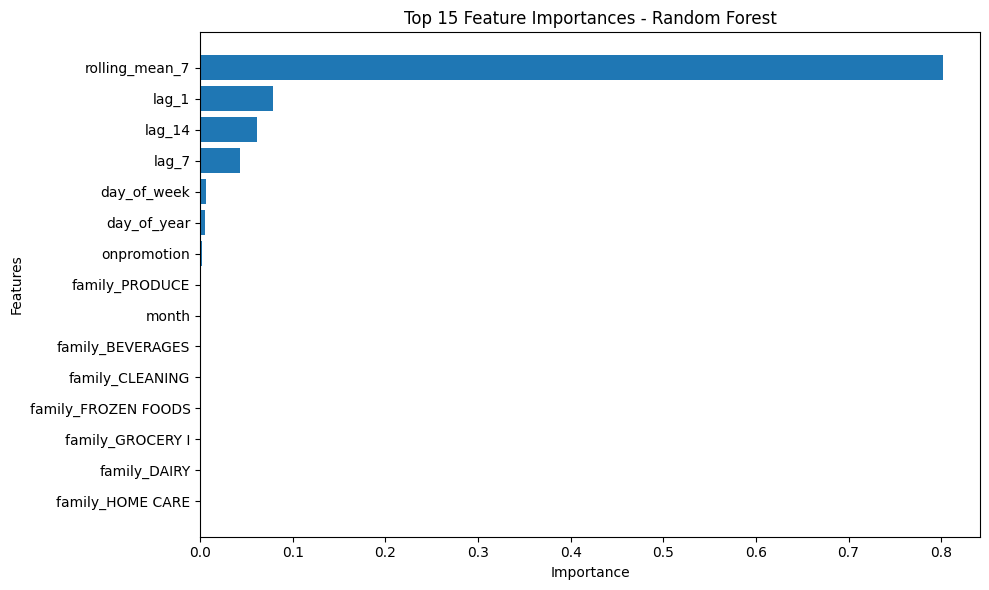

In [34]:
# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
display(feature_importance.head(15))

# Visualize feature importance
plt.figure(figsize=(10, 6))

top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [35]:
# Compare actual and predicted sales
error_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": rf_predictions
})

error_df["Error"] = (
    error_df["Actual"] - error_df["Predicted"]
)

error_df["Absolute_Error"] = error_df["Error"].abs()

display(error_df.head(10))

print("Mean Absolute Error:",
      round(error_df["Absolute_Error"].mean(), 2))

print("Maximum Absolute Error:",
      round(error_df["Absolute_Error"].max(), 2))

,Actual,Predicted,Error,Absolute_Error
0,334.0,341.606830,-7.606830,7.606830
1,301.0,318.741501,-17.741501,17.741501
2,310.0,307.725210,2.274790,2.274790
3,325.0,312.175112,12.824888,12.824888
4,353.0,339.484767,13.515233,13.515233
5,493.0,478.549832,14.450168,14.450168
6,489.0,517.979862,-28.979862,28.979862
7,347.0,325.423481,21.576519,21.576519
8,319.0,319.368550,-0.368550,0.368550
9,296.0,305.803047,-9.803047,9.803047


Mean Absolute Error: 1776.16
Maximum Absolute Error: 69386.18


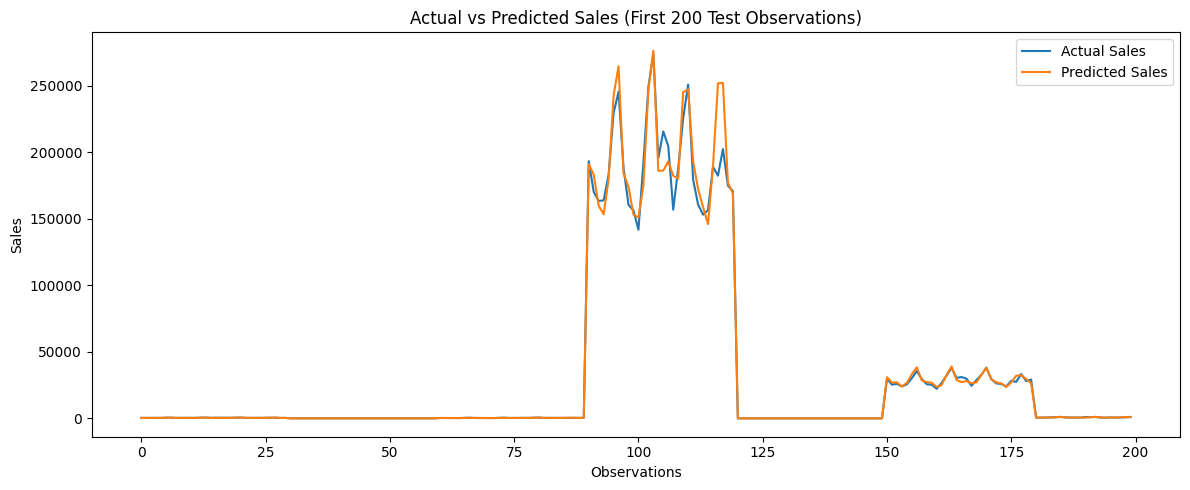

In [36]:
plt.figure(figsize=(12, 5))

plt.plot(
    y_test.values[:200],
    label="Actual Sales"
)

plt.plot(
    rf_predictions[:200],
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales (First 200 Test Observations)")
plt.xlabel("Observations")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

In [37]:
import os
import joblib

# Create model directory
os.makedirs("models", exist_ok=True)

# Save trained model
joblib.dump(rf_model, "models/random_forest_model.pkl")

# Save feature columns for future predictions
joblib.dump(list(X_train.columns), "models/model_features.pkl")

print("Model saved successfully!")

Model saved successfully!


## creating a clearer evaluation graph

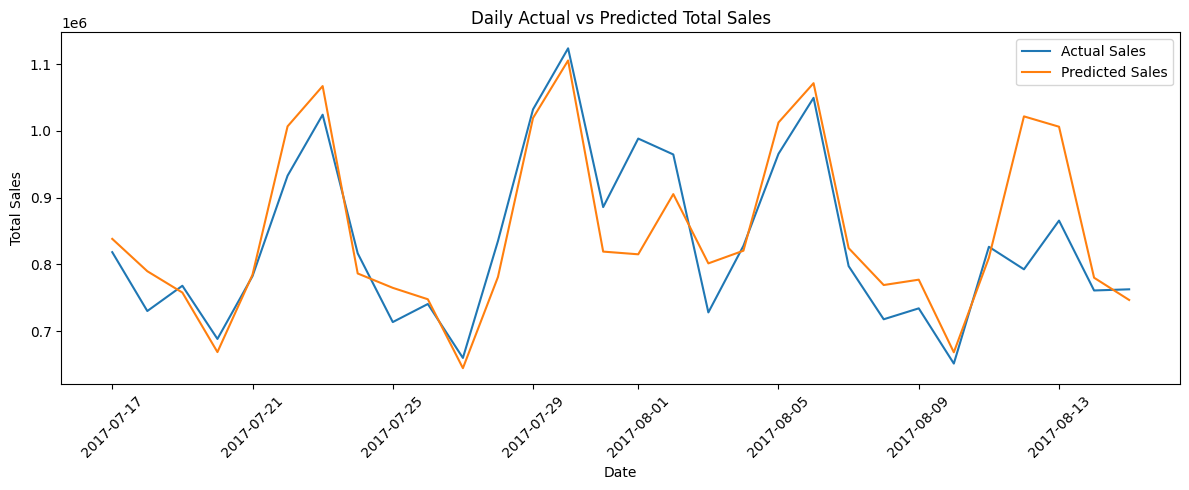

In [38]:
plot_df = pd.DataFrame({
    "date": test_df["date"].values,
    "actual_sales": y_test.values,
    "predicted_sales": rf_predictions
})

daily_comparison = plot_df.groupby("date", as_index=False).agg({
    "actual_sales": "sum",
    "predicted_sales": "sum"
})

plt.figure(figsize=(12, 5))
plt.plot(daily_comparison["date"],
         daily_comparison["actual_sales"],
         label="Actual Sales")

plt.plot(daily_comparison["date"],
         daily_comparison["predicted_sales"],
         label="Predicted Sales")

plt.title("Daily Actual vs Predicted Total Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Generating 7 day demand forecast

In [39]:
# Last available date
last_date = daily_data["date"].max()

# Get product families
families = sorted(daily_data["family"].unique())

# Store historical sales for each family
sales_history = {}

for family in families:
    sales_history[family] = daily_data[
        daily_data["family"] == family
    ]["sales"].tolist()

forecast_results = []

# Generate forecasts for 7 days
for day in range(1, 8):

    future_date = last_date + pd.Timedelta(days=day)

    for family in families:

        history = sales_history[family]

        # Initialize all model features with zero
        input_row = {col: 0 for col in X_train.columns}

        # Set numerical features
        input_row["onpromotion"] = 0
        input_row["day_of_week"] = future_date.dayofweek
        input_row["month"] = future_date.month
        input_row["day_of_year"] = future_date.dayofyear
        input_row["lag_1"] = history[-1]
        input_row["lag_7"] = history[-7]
        input_row["lag_14"] = history[-14]
        input_row["rolling_mean_7"] = np.mean(history[-7:])

        # Correctly encode the product family
        family_column = f"family_{family}"

        if family_column in input_row:
            input_row[family_column] = 1

        # Convert to DataFrame in training feature order
        input_data = pd.DataFrame(
            [input_row],
            columns=X_train.columns
        )

        # Predict demand
        prediction = rf_model.predict(input_data)[0]
        prediction = max(0, prediction)

        # Store result
        forecast_results.append({
            "date": future_date,
            "family": family,
            "predicted_sales": prediction
        })

        # Update history for recursive forecasting
        history.append(prediction)

# Create forecast DataFrame
forecast_df = pd.DataFrame(forecast_results)

print("Forecast shape:", forecast_df.shape)
display(forecast_df.head(10))

Forecast shape: (231, 3)


,date,family,predicted_sales
0,2017-08-16,AUTOMOTIVE,323.398258
1,2017-08-16,BABY CARE,7.301860
2,2017-08-16,BEAUTY,319.612777
3,2017-08-16,BEVERAGES,156310.180472
4,2017-08-16,BOOKS,0.271417
5,2017-08-16,BREAD/BAKERY,26154.504151
6,2017-08-16,CELEBRATION,616.851756
7,2017-08-16,CLEANING,54416.138855
8,2017-08-16,DAIRY,43223.736097
9,2017-08-16,DELI,14374.008885


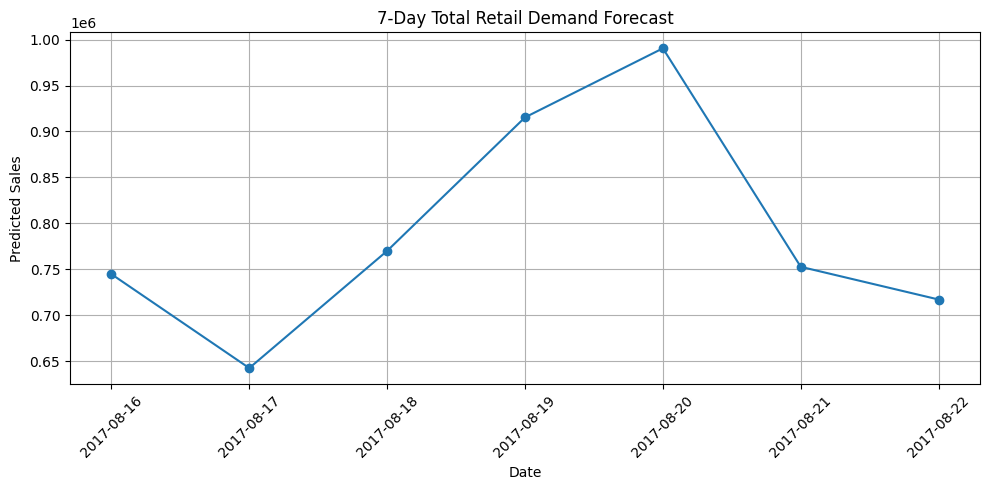

Corrected forecast saved successfully!


In [40]:
daily_forecast = forecast_df.groupby(
    "date"
)["predicted_sales"].sum()

plt.figure(figsize=(10, 5))
plt.plot(
    daily_forecast.index,
    daily_forecast.values,
    marker="o"
)

plt.title("7-Day Total Retail Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Predicted Sales")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

# Save corrected forecast
os.makedirs("artifacts", exist_ok=True)

forecast_df.to_csv(
    "artifacts/forecast.csv",
    index=False
)

print("Corrected forecast saved successfully!")

In [41]:
# Average predicted daily demand for each family
forecast_summary = forecast_df.groupby("family").agg(
    average_daily_demand=("predicted_sales", "mean"),
    total_7_day_demand=("predicted_sales", "sum")
).reset_index()

display(forecast_summary.head())

,family,average_daily_demand,total_7_day_demand
0,AUTOMOTIVE,372.752700,2.609269e+03
1,BABY CARE,7.561042,5.292730e+01
2,BEAUTY,359.691213,2.517838e+03
3,BEVERAGES,188247.821743,1.317735e+06
4,BOOKS,0.482101,3.374710e+00


In [42]:
# Historical demand statistics by product family
historical_stats = daily_data.groupby("family")["sales"].agg(
    average_demand="mean",
    demand_std="std"
).reset_index()

# Combine historical statistics and forecast
inventory_df = forecast_summary.merge(
    historical_stats,
    on="family",
    how="left"
)

# Reproducible simulated inventory assumptions
rng = np.random.default_rng(42)

inventory_df["lead_time_days"] = rng.integers(
    2, 8, size=len(inventory_df)
)

# Simulate current stock as 1–14 days of historical average demand
stock_coverage_days = rng.integers(
    1, 15, size=len(inventory_df)
)

inventory_df["current_stock"] = (
    inventory_df["average_demand"] * stock_coverage_days
).round().astype(int)

# Safety stock: 95% service-level assumption
z_score = 1.65

inventory_df["safety_stock"] = (
    z_score
    * inventory_df["demand_std"]
    * np.sqrt(inventory_df["lead_time_days"])
).round().astype(int)

# Reorder point = lead-time demand + safety stock
inventory_df["reorder_point"] = (
    inventory_df["average_daily_demand"]
    * inventory_df["lead_time_days"]
    + inventory_df["safety_stock"]
).round().astype(int)

# Target stock covers lead time + next 7 days + safety stock
inventory_df["target_stock"] = (
    inventory_df["average_daily_demand"]
    * (inventory_df["lead_time_days"] + 7)
    + inventory_df["safety_stock"]
).round().astype(int)

# Calculate recommended order quantity
inventory_df["recommended_order_qty"] = np.where(
    inventory_df["current_stock"] <= inventory_df["reorder_point"],
    np.maximum(
        0,
        inventory_df["target_stock"] - inventory_df["current_stock"]
    ),
    0
).astype(int)

# Determine stock status
inventory_df["stock_status"] = np.where(
    inventory_df["current_stock"] <= inventory_df["reorder_point"],
    "REORDER NOW",
    "SUFFICIENT STOCK"
)

display(inventory_df.head(10))

,family,average_daily_demand,total_7_day_demand,average_demand,demand_std,lead_time_days,current_stock,safety_stock,reorder_point,target_stock,recommended_order_qty,stock_status
0,AUTOMOTIVE,372.752700,2.609269e+03,330.454491,108.215649,2,2644,253,999,3608,0,SUFFICIENT STOCK
1,BABY CARE,7.561042,5.292730e+01,6.018563,7.961502,6,78,32,77,130,0,SUFFICIENT STOCK
2,BEAUTY,359.691213,2.517838e+03,201.169461,100.492952,5,201,371,2169,4687,4486,REORDER NOW
3,BEVERAGES,188247.821743,1.317735e+06,129440.631138,63005.015681,4,1682728,207917,960908,2278643,0,SUFFICIENT STOCK
4,BOOKS,0.482101,3.374710e+00,3.855090,13.018467,4,46,43,45,48,0,SUFFICIENT STOCK
5,BREAD/BAKERY,27912.992558,1.953909e+05,25079.147089,6480.097508,7,100317,28289,223680,419071,318754,REORDER NOW
6,CELEBRATION,700.766461,4.905365e+03,455.794611,408.413528,2,4102,953,2355,7260,0,SUFFICIENT STOCK
7,CLEANING,60330.619646,4.223143e+05,57976.411377,15165.977710,6,173929,61296,423280,845594,671665,REORDER NOW
8,DAIRY,43575.193580,3.050264e+05,38472.046707,13634.369034,3,423193,38965,169691,474717,0,SUFFICIENT STOCK
9,DELI,17065.198373,1.194564e+05,14351.545342,4155.748466,2,143515,9697,43827,163284,0,SUFFICIENT STOCK


In [43]:
print("Total Product Families:",
      inventory_df["family"].nunique())

print("Total Current Stock:",
      inventory_df["current_stock"].sum())

print("Total Recommended Order:",
      inventory_df["recommended_order_qty"].sum())

print("Categories Requiring Reorder:",
      (inventory_df["stock_status"] == "REORDER NOW").sum())

print("\nStock Status:")
print(inventory_df["stock_status"].value_counts())

Total Product Families: 33
Total Current Stock: 7020174
Total Recommended Order: 1840780
Categories Requiring Reorder: 17

Stock Status:
stock_status
REORDER NOW         17
SUFFICIENT STOCK    16
Name: count, dtype: int64


In [45]:
inventory_df.to_csv(
    "artifacts/inventory.csv",
    index=False
)

print("Inventory recommendations saved successfully!")

Inventory recommendations saved successfully!


### verifying that our rolling features do not cause data leakage.

In [46]:
family = "GROCERY I"

check = daily_data[
    daily_data["family"] == family
][["date", "sales", "lag_1", "lag_7", "rolling_mean_7"]].head(10)

display(check)

,date,sales,lag_1,lag_7,rolling_mean_7
20040,2013-01-15,114578.0,112128.0,133290.0,127841.857143
20041,2013-01-16,124276.0,114578.0,115871.0,125168.714286
20042,2013-01-17,103443.0,124276.0,96200.0,126369.428571
20043,2013-01-18,106982.0,103443.0,103280.0,127404.142857
20044,2013-01-19,165079.0,106982.0,151025.0,127933.000000
20045,2013-01-20,180666.0,165079.0,183099.0,129940.714286
20046,2013-01-21,122481.0,180666.0,112128.0,129593.142857
20047,2013-01-22,123066.0,122481.0,114578.0,131072.142857
20048,2013-01-23,112342.0,123066.0,124276.0,132284.714286
20049,2013-01-24,96882.0,112342.0,103443.0,130579.857143


### verify the rolling averages across the entire dataset

In [49]:
import numpy as np

expected_rolling = (
    daily_data.groupby("family")["sales"]
    .transform(lambda x: x.shift(1).rolling(window=7).mean())
)

# Compare only rows where the recalculated rolling average exists
valid_rows = expected_rolling.notna()

verification = np.allclose(
    daily_data.loc[valid_rows, "rolling_mean_7"],
    expected_rolling.loc[valid_rows]
)

print("Rolling feature verification:", verification)

Rolling feature verification: True


### Prediction error analysis

In [50]:
error_df = pd.DataFrame({
    "date": test_df["date"].values,
    "actual_sales": y_test.values,
    "predicted_sales": rf_predictions
})

error_df["absolute_error"] = abs(
    error_df["actual_sales"] - error_df["predicted_sales"]
)

error_df = error_df.sort_values(
    "absolute_error", ascending=False
)

display(error_df.head(10))

,date,actual_sales,predicted_sales,absolute_error
116,2017-08-12,182318.0000,251704.177316,69386.177316
386,2017-08-12,238627.6330,303494.476416,64866.843416
375,2017-08-01,301453.4920,248416.595608,53036.896392
117,2017-08-13,202354.0000,252022.903320,49668.903320
387,2017-08-13,258442.4520,297038.686776,38596.234776
374,2017-07-31,270215.6660,235781.953148,34433.712852
225,2017-08-01,103895.0000,71533.308476,32361.691524
105,2017-08-01,215546.0000,186131.715097,29414.284903
376,2017-08-02,281631.3380,253998.134879,27633.203121
926,2017-08-12,111788.3509,138986.339518,27197.988618


### Identifying the affected product families

In [51]:
error_analysis = pd.DataFrame({
    "date": test_df["date"].values,
    "family": daily_data.loc[test_df.index, "family"].values,
    "actual_sales": y_test.values,
    "predicted_sales": rf_predictions,
    "onpromotion": daily_data.loc[test_df.index, "onpromotion"].values,
    "lag_1": X_test["lag_1"].values,
    "rolling_mean_7": X_test["rolling_mean_7"].values
})

error_analysis["absolute_error"] = abs(
    error_analysis["actual_sales"] -
    error_analysis["predicted_sales"]
)

error_analysis = error_analysis.sort_values(
    "absolute_error", ascending=False
)

display(error_analysis.head(10))

,date,family,actual_sales,predicted_sales,onpromotion,lag_1,rolling_mean_7,absolute_error
116,2017-08-12,BEVERAGES,182318.0000,251704.177316,956,189111.000,187841.428571,69386.177316
386,2017-08-12,GROCERY I,238627.6330,303494.476416,2325,238221.922,244049.292286,64866.843416
375,2017-08-01,GROCERY I,301453.4920,248416.595608,2790,270215.666,249842.655571,53036.896392
117,2017-08-13,BEVERAGES,202354.0000,252022.903320,986,182318.000,181675.285714,49668.903320
387,2017-08-13,GROCERY I,258442.4520,297038.686776,2320,238627.633,236380.040143,38596.234776
374,2017-07-31,GROCERY I,270215.6660,235781.953148,3314,328519.734,245624.884000,34433.712852
225,2017-08-01,CLEANING,103895.0000,71533.308476,923,89385.000,82233.142857,32361.691524
105,2017-08-01,BEVERAGES,215546.0000,186131.715097,1461,195504.000,195543.714286,29414.284903
376,2017-08-02,GROCERY I,281631.3380,253998.134879,3063,301453.492,262766.580714,27633.203121
926,2017-08-12,PRODUCE,111788.3509,138986.339518,324,118738.143,122702.969490,27197.988618


In [52]:
family_error = (
    error_analysis.groupby("family")
    .agg(
        mean_absolute_error=("absolute_error", "mean"),
        maximum_error=("absolute_error", "max"),
        total_errors=("absolute_error", "count")
    )
    .sort_values("mean_absolute_error", ascending=False)
    .reset_index()
)

display(family_error.head(10))

,family,mean_absolute_error,maximum_error,total_errors
0,GROCERY I,15637.447845,64866.843416,30
1,BEVERAGES,12944.187903,69386.177316,30
2,CLEANING,8565.425860,32361.691524,30
3,PRODUCE,6745.492048,27197.988618,30
4,DAIRY,2546.073637,13607.667990,30
5,PERSONAL CARE,1725.492155,7097.471829,30
6,BREAD/BAKERY,1418.702339,4637.881596,30
7,HOME CARE,1417.751348,4675.270260,30
8,DELI,1271.557423,5241.538681,30
9,MEATS,1103.759440,4283.881822,30


In [54]:
# Calculate average actual sales for each family
family_actual = (
    error_analysis.groupby("family")["actual_sales"]
    .mean()
    .reset_index(name="mean_actual_sales")
)

# Merge using family name
family_error = family_error.drop(
    columns=["mean_actual_sales", "mae_percentage"],
    errors="ignore"
)

family_error = family_error.merge(
    family_actual,
    on="family",
    how="left"
)

# Calculate percentage MAE
family_error["mae_percentage"] = (
    family_error["mean_absolute_error"]
    / family_error["mean_actual_sales"]
) * 100

display(
    family_error[
        ["family", "mean_absolute_error", "mean_actual_sales", "mae_percentage"]
    ].sort_values("mae_percentage", ascending=False).head(10)
)

,family,mean_absolute_error,mean_actual_sales,mae_percentage
32,BOOKS,1.218858,0.966667,126.088808
15,PLAYERS AND ELECTRONICS,395.651416,619.033333,63.914396
31,BABY CARE,3.362300,9.600000,35.023960
30,HOME APPLIANCES,4.376935,12.766667,34.284087
19,LADIESWEAR,192.192715,578.733333,33.209201
12,SCHOOL AND OFFICE SUPPLIES,578.226156,1923.833333,30.055938
24,LINGERIE,66.509628,375.900000,17.693437
29,HARDWARE,11.315325,77.766667,14.550353
16,HOME AND KITCHEN II,231.930267,1656.966667,13.997280
25,MAGAZINES,47.315672,367.033333,12.891383


### Evaluating additional ML models

In [55]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Decision Tree": DecisionTreeRegressor(
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

model_comparison = pd.DataFrame(results)

display(model_comparison)

,Model,MAE,RMSE,R2
0,Decision Tree,2598.677112,8131.308077,0.978908
1,Gradient Boosting,2091.267603,5942.363834,0.988735


In [56]:
import os
import pandas as pd

final_comparison = pd.DataFrame([
    {
        "Model": "7-Day Baseline",
        "MAE": 2789.678158,
        "RMSE": 9223.152766,
        "R2": 0.972863
    },
    {
        "Model": "Decision Tree",
        "MAE": 2598.677112,
        "RMSE": 8131.308077,
        "R2": 0.978908
    },
    {
        "Model": "Gradient Boosting",
        "MAE": 2091.267603,
        "RMSE": 5942.363834,
        "R2": 0.988735
    },
    {
        "Model": "Random Forest",
        "MAE": 1776.162123,
        "RMSE": 5756.369873,
        "R2": 0.989429
    }
])

os.makedirs("artifacts", exist_ok=True)

final_comparison.to_csv(
    "artifacts/model_comparison.csv",
    index=False
)

display(final_comparison)
print("Model comparison saved successfully!")

,Model,MAE,RMSE,R2
0,7-Day Baseline,2789.678158,9223.152766,0.972863
1,Decision Tree,2598.677112,8131.308077,0.978908
2,Gradient Boosting,2091.267603,5942.363834,0.988735
3,Random Forest,1776.162123,5756.369873,0.989429


Model comparison saved successfully!
